# SMS Spam Classification using SVM (improved version)

**Goal:** automatically decide whether a text message is **spam** or **ham** (a normal message).
**Dataset:** [SMS Spam Collection (Kaggle / UCI)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset) - about 5,500 labelled English SMS messages.

### How to run this notebook
1. **Google Colab:** upload this file to Colab, then click *Runtime > Run all*. The data is downloaded automatically.
2. **Your own computer:** run `pip install -r requirements.txt`, then open the notebook in Jupyter and click *Run All*.
3. *(Optional)* To use your own Kaggle file, save it as `data/spam.csv`. The notebook will use it first.

### What was improved compared to the starter notebook
| # | Problem in the starter version | Fix in this version |
|---|---|---|
| 1 | Only worked in Colab (`google.colab`), and the file name did not match (`spam.csv` vs `SMS.csv`) | Works anywhere; loads `data/spam.csv` or downloads the data automatically |
| 2 | Duplicate messages were removed **after** the charts, so the charts counted them | Duplicates removed first, so every step uses the same clean data |
| 3 | Numbers, links and money signs were deleted, but these are strong spam clues | They are replaced by special words (e.g. `urltoken`, `moneytoken`) so the model can still use them |
| 4 | Accuracy only. Spam is ~13% of the data, so accuracy can look good while missing spam | Uses **precision, recall and F1** for the spam class |
| 5 | Final model never tested on the held-out test set; cross-validation on all data re-used the test rows | Test set is touched **once**, at the very end |
| 6 | Only one model and one setting (`C`) was tried | Compares 5 models and tunes 5 settings of the SVM |
| 7 | No confusion matrix, ROC or error analysis (imported but unused) | Added confusion matrix, ROC and Precision-Recall curves, mistakes list, most important words |
| 8 | No record of library versions, so results could differ between computers | Versions are printed, `requirements.txt` is included, and one `SEED` is used so results repeat |

## 1. Setup

In [1]:
# Only needed on a fresh machine. Remove the leading "#" if you see "ModuleNotFoundError".
# %pip install -q wordcloud nltk scikit-learn seaborn pandas matplotlib

In [2]:
import re, csv, string, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score)

SEED = 42                      # one seed for the whole notebook -> same results every run
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.12.3 | scikit-learn 1.8.0 | pandas 3.0.2


## 2. Load the data
The notebook first looks for the Kaggle file `data/spam.csv`. If it is not there, it downloads the same SMS Spam Collection from a public copy.

In [3]:
KAGGLE_FILE = Path("data/spam.csv")
MIRROR_URL = ("https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/"
              "master/data/sms.tsv")

if KAGGLE_FILE.exists():
    raw = pd.read_csv(KAGGLE_FILE, encoding="latin-1")[["v1", "v2"]]
    raw.columns = ["label", "message"]
    print("Loaded", KAGGLE_FILE)
else:
    raw = pd.read_csv(MIRROR_URL, sep="\t", header=None, names=["label", "message"],
                      quoting=csv.QUOTE_NONE)
    print("data/spam.csv not found -> downloaded the public copy of the dataset")

print("Shape:", raw.shape)
raw.head()

data/spam.csv not found -> downloaded the public copy of the dataset
Shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 3. Check data quality
Exact duplicate messages are removed **before** anything else. If the same message were in both the training and the test set, the score would look better than it really is.

In [4]:
print("Missing values:\n", raw.isnull().sum(), "\n")
assert set(raw["label"].unique()) == {"ham", "spam"}, "Unexpected labels in the data"

n_dup = raw.duplicated().sum()
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {n_dup}  ->  {len(df)} unique messages remain")

df["label_name"] = df["label"]                       # 'ham' / 'spam' (for charts)
df["label"] = df["label_name"].map({"ham": 0, "spam": 1})   # 0 / 1 (for the model)

counts = df["label_name"].value_counts()
print("\nClass counts:\n", counts)
print(f"Spam share: {counts['spam'] / len(df):.1%}  (imbalanced -> accuracy alone is not enough)")

Missing values:
 label      0
message    0
dtype: int64 

Duplicate rows removed: 403  ->  5171 unique messages remain

Class counts:
 label_name
ham     4518
spam     653
Name: count, dtype: int64
Spam share: 12.6%  (imbalanced -> accuracy alone is not enough)


## 4. Exploratory data analysis

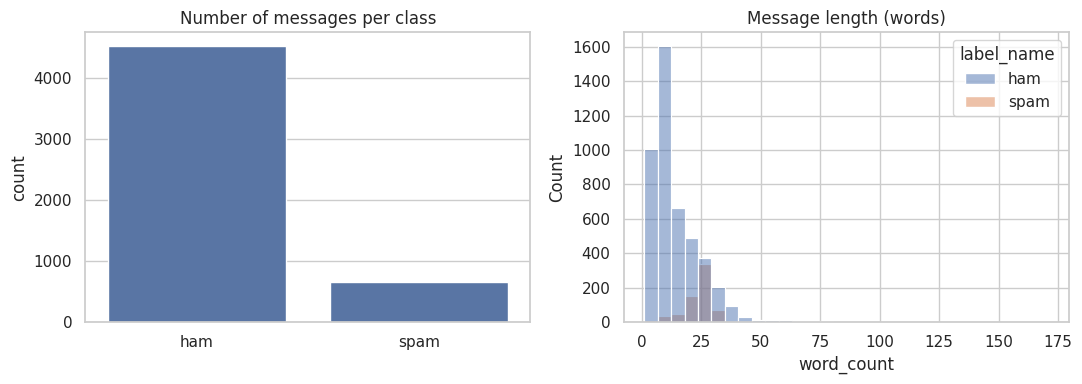

In [5]:
df["char_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()
df["digit_count"] = df["message"].str.count(r"\d")
df["has_url"] = df["message"].str.contains(r"http|www\.", case=False)
df["has_currency"] = df["message"].str.contains(r"[£$€]")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="label_name", order=["ham", "spam"], ax=ax[0])
ax[0].set_title("Number of messages per class"); ax[0].set_xlabel("")
sns.histplot(data=df, x="word_count", hue="label_name", bins=30, ax=ax[1])
ax[1].set_title("Message length (words)")
plt.tight_layout(); save_fig("class_balance_and_length"); plt.show()

In [6]:
summary = df.groupby("label_name").agg(
    avg_words=("word_count", "mean"),
    avg_digits=("digit_count", "mean"),
    pct_with_link=("has_url", "mean"),
    pct_with_currency_sign=("has_currency", "mean"),
)
summary[["pct_with_link", "pct_with_currency_sign"]] *= 100   # turn shares into percentages
summary.round(1)

,avg_words,avg_digits,pct_with_link,pct_with_currency_sign
label_name,,,,
ham,14.2,0.3,0.0,0.4
spam,23.7,15.5,13.9,33.2


**What this tells us:** spam messages are longer and contain many more digits (phone numbers, prices, codes). This is the reason the improved cleaning step (section 5) **keeps** a signal for numbers, links and money signs instead of deleting them.

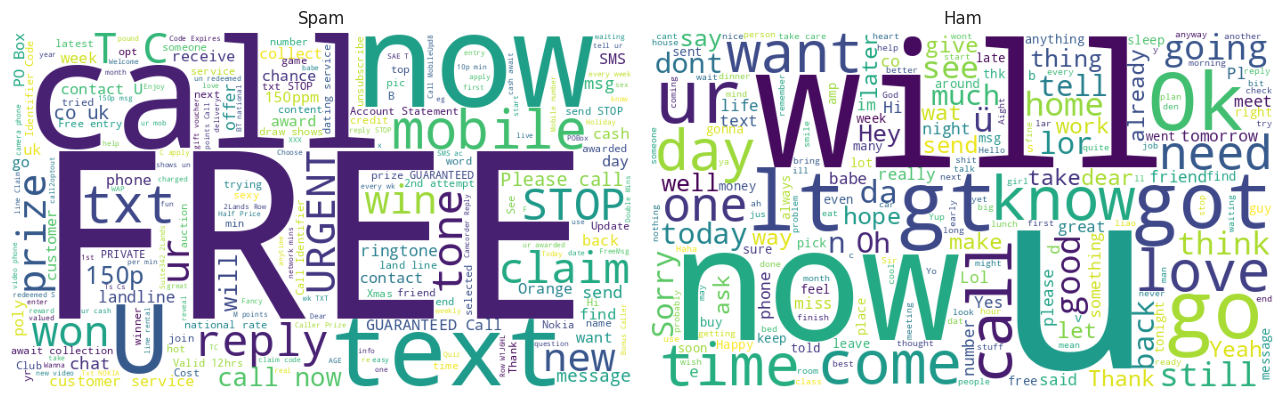

In [7]:
spam_text = " ".join(df.loc[df.label == 1, "message"])
ham_text = " ".join(df.loc[df.label == 0, "message"])

plt.figure(figsize=(13, 5))
for i, (title, text) in enumerate([("Spam", spam_text), ("Ham", ham_text)], 1):
    plt.subplot(1, 2, i)
    plt.imshow(WordCloud(background_color="white", width=700, height=400,
                         random_state=SEED).generate(text))
    plt.axis("off"); plt.title(title)
plt.tight_layout(); save_fig("wordclouds"); plt.show()

## 5. Text cleaning
Three versions of the text are prepared so we can **measure** which one works best (instead of guessing):

* **raw** - only lowercase. No other cleaning.
* **original** - the cleaning from the starter notebook (deletes links, numbers, punctuation, stop-words).
* **improved** - same idea, but links, numbers and money signs become special words.

In [8]:
STOP_WORDS = set(stopwords.words("english"))
lemm = WordNetLemmatizer()
PUNCT_TABLE = str.maketrans("", "", string.punctuation)

def clean_raw(text):
    return text.lower()

def clean_original(text):
    """The starter notebook's cleaning (kept unchanged for a fair comparison)."""
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(PUNCT_TABLE)
    return " ".join(lemm.lemmatize(w) for w in text.split() if w not in STOP_WORDS)

def clean_improved(text):
    """Keeps the *presence* of links, emails, money signs and numbers as special words."""
    text = text.lower()
    text = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", text)
    text = re.sub(r"\S+@\S+\.\S+", " emailtoken ", text)
    text = re.sub(r"[£$€]", " moneytoken ", text)
    text = re.sub(r"\d{5,}", " longnumtoken ", text)      # phone numbers, short codes
    text = re.sub(r"\d+", " numtoken ", text)             # other numbers
    text = text.translate(PUNCT_TABLE)
    return " ".join(lemm.lemmatize(w) for w in text.split() if w not in STOP_WORDS)

CLEANERS = {"raw": clean_raw, "original": clean_original, "improved": clean_improved}

example = "WINNER!! You won £1000. Call 09061701461 now or visit www.prize-claim.com"
for name, fn in CLEANERS.items():
    print(f"{name:>9}: {fn(example)}")

for name, fn in CLEANERS.items():
    df[f"text_{name}"] = df["message"].apply(fn)

      raw: winner!! you won £1000. call 09061701461 now or visit www.prize-claim.com


 original: winner £ call visit
 improved: winner moneytoken numtoken call longnumtoken visit urltoken


## 6. Train / test split
80% of the messages are used for training and model selection. The remaining 20% is the **test set**. It is kept locked away and used **only once** in section 9.
`stratify` keeps the same spam share in both parts.

In [9]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df["label"])
y_train, y_test = train_df["label"], test_df["label"]
print("Train:", train_df.shape[0], "messages | Test:", test_df.shape[0], "messages")
print("Spam share  train: {:.1%}  test: {:.1%}".format(y_train.mean(), y_test.mean()))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # used on training data only
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}

def cv_table(results):
    """results: {name: cross_validate output} -> tidy table of mean scores."""
    rows = {name: {m: r[f"test_{m}"].mean() for m in scoring} for name, r in results.items()}
    return pd.DataFrame(rows).T.round(4)

Train: 4136 messages | Test: 1035 messages
Spam share  train: 12.6%  test: 12.7%


## 7. Which text cleaning works best?
Same model (Linear SVM) and same 5-fold cross-validation on the **training** data. Only the text differs.
The main score is **F1 of the spam class** (a balance between catching spam and not blocking real messages).

In [10]:
def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)), ("clf", clf)])

prep_results = {
    name: cross_validate(make_pipe(LinearSVC()), train_df[f"text_{name}"], y_train,
                         cv=cv, scoring=scoring, n_jobs=-1)
    for name in CLEANERS
}
prep_table = cv_table(prep_results)
display(prep_table)

BEST_CLEANER = prep_table["f1"].idxmax()
print(f"-> Best cleaning by cross-validated F1: '{BEST_CLEANER}'")
TEXT_COL = f"text_{BEST_CLEANER}"

,accuracy,precision,recall,f1
raw,0.9857,0.9817,0.9042,0.9411
original,0.9775,0.9671,0.8505,0.9049
improved,0.9872,0.9794,0.9175,0.9472


-> Best cleaning by cross-validated F1: 'improved'


## 8. Compare models, then tune the SVM
### 8.1 Five models on the chosen text (5-fold cross-validation on training data)

,accuracy,precision,recall,f1
Linear SVM,0.9872,0.9794,0.9175,0.9472
Linear SVM (balanced),0.9857,0.9536,0.9329,0.9425
RBF SVM,0.9836,0.9850,0.8830,0.9304
Naive Bayes,0.9785,0.9907,0.8370,0.9065
Logistic Regression,0.9695,0.9480,0.8026,0.8682


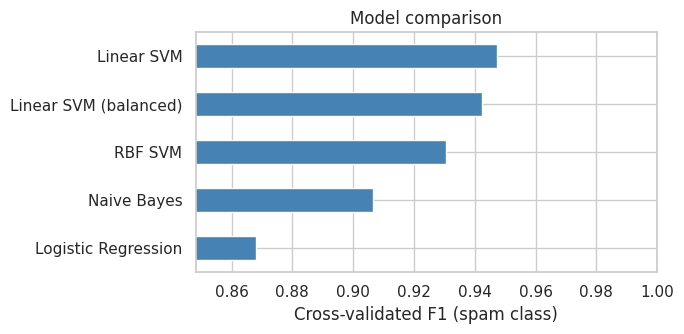

In [11]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Linear SVM (balanced)": LinearSVC(class_weight="balanced"),
    "RBF SVM": SVC(kernel="rbf"),
}
model_results = {
    name: cross_validate(make_pipe(clf), train_df[TEXT_COL], y_train,
                         cv=cv, scoring=scoring, n_jobs=-1)
    for name, clf in models.items()
}
model_table = cv_table(model_results).sort_values("f1", ascending=False)
display(model_table)

ax = model_table["f1"].sort_values().plot.barh(figsize=(7, 3.5), color="steelblue")
ax.set_xlabel("Cross-validated F1 (spam class)"); ax.set_title("Model comparison")
ax.set_xlim(model_table["f1"].min() - 0.02, 1.0)
plt.tight_layout(); save_fig("model_comparison"); plt.show()

### 8.2 Tune the Linear SVM
`GridSearchCV` tries every combination below with 5-fold cross-validation (training data only) and keeps the one with the best **F1**.

In [12]:
pipe = Pipeline([("tfidf", TfidfVectorizer()), ("clf", LinearSVC())])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],       # single words, or words + word pairs
    "tfidf__min_df": [1, 2],                      # ignore words that appear in fewer than N messages
    "tfidf__sublinear_tf": [True, False],         # dampen very frequent words
    "clf__C": [0.1, 0.3, 1, 3, 10],               # how strictly the SVM fits the training data
    "clf__class_weight": [None, "balanced"],      # give spam more weight (it is the rarer class)
}

grid = GridSearchCV(pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(train_df[TEXT_COL], y_train)

print("Best settings:", grid.best_params_)
print(f"Best cross-validated F1: {grid.best_score_:.4f}")

top = (pd.DataFrame(grid.cv_results_)
         .sort_values("rank_test_score")
         .head(5)[["rank_test_score", "mean_test_score", "std_test_score", "params"]])
top.round(4)

Best settings: {'clf__C': 10, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best cross-validated F1: 0.9530


,rank_test_score,mean_test_score,std_test_score,params
66,1,0.9530,0.0156,"{'clf__C': 10, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}"
58,2,0.9521,0.0146,"{'clf__C': 3, 'clf__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}"
74,2,0.9521,0.0146,"{'clf__C': 10, 'clf__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}"
67,4,0.9520,0.0145,"{'clf__C': 10, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': False}"
50,5,0.9519,0.0156,"{'clf__C': 3, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}"


## 9. Final evaluation on the test set (used once)
We compare two models on the **same** test messages:
* **Starter model** - exactly what the starter notebook did (original cleaning, `max_features=5000`, `C` chosen by accuracy).
* **Improved model** - the tuned model from section 8.

In [13]:
# --- Starter model, re-created exactly as in the original notebook -----------------
starter = GridSearchCV(
    Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
              ("clf", LinearSVC())]),
    {"clf__C": [0.1, 1, 10]}, cv=5, n_jobs=-1)           # default scoring = accuracy
starter.fit(train_df["text_original"], y_train)
starter_pred = starter.predict(test_df["text_original"])

# --- Improved model ---------------------------------------------------------------
best_model = grid.best_estimator_
pred = best_model.predict(test_df[TEXT_COL])
scores = best_model.decision_function(test_df[TEXT_COL])   # > 0 means "spam"

def evaluate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "Real messages blocked (FP)": fp,
            "Spam missed (FN)": fn}

comparison = pd.DataFrame({"Starter model": evaluate(y_test, starter_pred),
                           "Improved model": evaluate(y_test, pred)})
display(comparison.round(4))
print("Test set size:", len(y_test), "| spam messages in it:", int(y_test.sum()))

,Starter model,Improved model
Accuracy,0.9836,0.9874
Precision,0.9672,0.9609
Recall,0.9008,0.9389
F1,0.9328,0.9498
Real messages blocked (FP),4.0000,5.0000
Spam missed (FN),13.0000,8.0000


Test set size: 1035 | spam messages in it: 131


In [14]:
print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=4))

              precision    recall  f1-score   support

         ham     0.9912    0.9945    0.9928       904
        spam     0.9609    0.9389    0.9498       131

    accuracy                         0.9874      1035
   macro avg     0.9761    0.9667    0.9713      1035
weighted avg     0.9874    0.9874    0.9874      1035



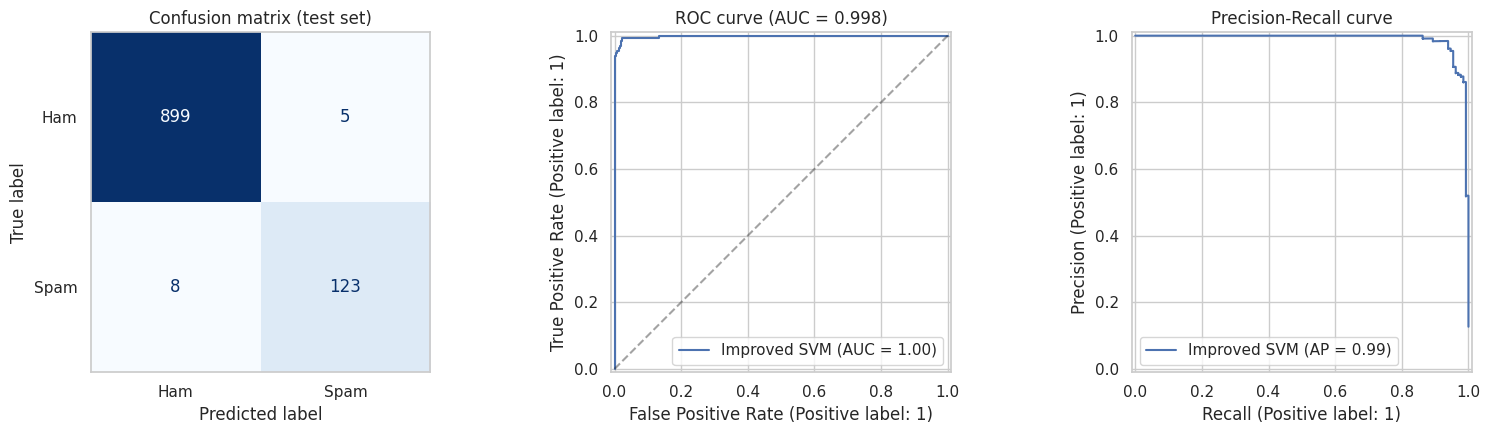

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Ham", "Spam"],
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test set)"); ax[0].grid(False)

RocCurveDisplay.from_predictions(y_test, scores, ax=ax[1], name="Improved SVM")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4); ax[1].set_title(f"ROC curve (AUC = {roc_auc_score(y_test, scores):.3f})")

PrecisionRecallDisplay.from_predictions(y_test, scores, ax=ax[2], name="Improved SVM")
ax[2].set_title("Precision-Recall curve")

plt.tight_layout(); save_fig("evaluation"); plt.show()

## 10. Error analysis - which messages does the model get wrong?
Looking at the mistakes helps explain the limits of the model.

In [16]:
errors = test_df.assign(predicted=pred)[["message", "label", "predicted"]]
errors["label"] = errors["label"].map({0: "ham", 1: "spam"})
errors["predicted"] = errors["predicted"].map({0: "ham", 1: "spam"})
errors = errors[errors["label"] != errors["predicted"]]

print("Real messages wrongly marked as SPAM (false positives):")
display(errors[errors["label"] == "ham"][["message"]])
print("Spam that was MISSED (false negatives):")
display(errors[errors["label"] == "spam"][["message"]])

Real messages wrongly marked as SPAM (false positives):


,message
487,Are you free now?can i call now?
4080,Ü only send me the contents page...
1620,Glad to see your reply.
177,Text her. If she doesnt reply let me know so i can have her log in
2890,Your bill at 3 is £33.65 so thats not bad!


Spam that was MISSED (false negatives):


,message
4499,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
521,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750
2642,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...
3332,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. ..."
1813,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...
3890,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ..."
5064,"Latest News! Police station toilet stolen, cops have nothing to go on!"


## 11. What did the model learn? (most important words)
For a linear SVM, each word has a weight. Large positive weight = pushes towards **spam**; large negative = pushes towards **ham**.

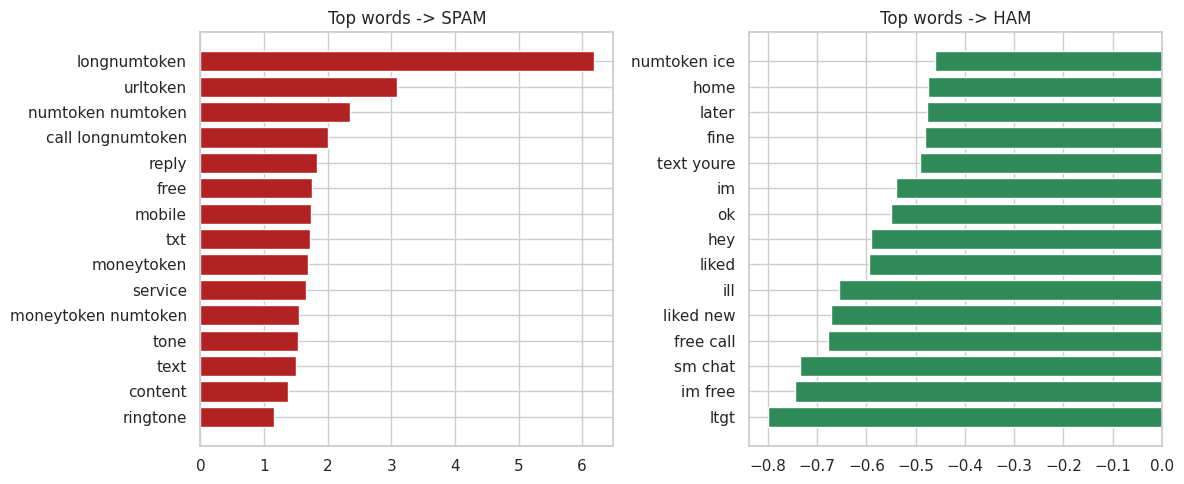

In [17]:
vec = best_model.named_steps["tfidf"]
weights = best_model.named_steps["clf"].coef_.ravel()
words = np.array(vec.get_feature_names_out())
order = np.argsort(weights)
top_ham, top_spam = order[:15], order[-15:]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(words[top_spam], weights[top_spam], color="firebrick"); ax[0].set_title("Top words -> SPAM")
ax[1].barh(words[top_ham], weights[top_ham], color="seagreen");    ax[1].set_title("Top words -> HAM")
plt.tight_layout(); save_fig("top_words"); plt.show()

## 12. Try it on new messages

In [18]:
CLEAN = CLEANERS[BEST_CLEANER]

def predict_sms(text):
    """Returns the label and a score. Score > 0 = spam; the further from 0, the more confident."""
    score = best_model.decision_function([CLEAN(text)])[0]
    return {"label": "Spam" if score > 0 else "Ham", "score": round(float(score), 2)}

samples = [
    "Congratulations! You have won a free iPhone. Click http://claim-now.com to collect.",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! Your mobile number has won a 2000 prize. Call 09061701461 now",
    "Can you send me the notes from today's lecture?",
]
for s in samples:
    print(predict_sms(s), "<-", s)

{'label': 'Spam', 'score': 0.75} <- Congratulations! You have won a free iPhone. Click http://claim-now.com to collect.
{'label': 'Ham', 'score': -1.09} <- Hi, are we meeting tomorrow at 3 PM?
{'label': 'Spam', 'score': 1.7} <- URGENT! Your mobile number has won a 2000 prize. Call 09061701461 now
{'label': 'Ham', 'score': -0.91} <- Can you send me the notes from today's lecture?


## 13. Summary

In [19]:
f1_starter = comparison.loc["F1", "Starter model"]
f1_improved = comparison.loc["F1", "Improved model"]
print(f"Best text cleaning (cross-validation): {BEST_CLEANER}")
print(f"Best settings: {grid.best_params_}")
print(f"Test F1 - starter model : {f1_starter:.4f}")
print(f"Test F1 - improved model: {f1_improved:.4f}")
print(f"Test ROC AUC (improved) : {roc_auc_score(y_test, scores):.4f}")

Best text cleaning (cross-validation): improved
Best settings: {'clf__C': 10, 'clf__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Test F1 - starter model : 0.9328
Test F1 - improved model: 0.9498
Test ROC AUC (improved) : 0.9980


### Limitations and ideas for future work
* The test set is small (about 1,000 messages, ~130 of them spam). One extra mistake changes the scores by roughly 0.5-1 percentage point, so **small differences between models are not reliable**.
* Messages are English only and come from one collection (mostly 2000s UK/Singapore texts). Modern spam looks different, so the model would need re-training on newer data.
* Possible next steps: nested cross-validation, word embeddings (e.g. sentence-transformers), and checking the model on a second, independent dataset.